In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

## Data Analysis

In [2]:
df=pd.read_csv("dataset.csv")

In [3]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 9551 entries, 0 to 9550
Data columns (total 21 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   Restaurant ID         9551 non-null   int64  
 1   Restaurant Name       9551 non-null   object 
 2   Country Code          9551 non-null   int64  
 3   City                  9551 non-null   object 
 4   Address               9551 non-null   object 
 5   Locality              9551 non-null   object 
 6   Locality Verbose      9551 non-null   object 
 7   Longitude             9551 non-null   float64
 8   Latitude              9551 non-null   float64
 9   Cuisines              9542 non-null   object 
 10  Average Cost for two  9551 non-null   int64  
 11  Currency              9551 non-null   object 
 12  Has Table booking     9551 non-null   object 
 13  Has Online delivery   9551 non-null   object 
 14  Is delivering now     9551 non-null   object 
 15  Switch to order menu 

In [4]:
df.describe()

,Restaurant ID,Country Code,Longitude,Latitude,Average Cost for two,Price range,Aggregate rating,Votes
count,9.551000e+03,9551.000000,9551.000000,9551.000000,9551.000000,9551.000000,9551.000000,9551.000000
mean,9.051128e+06,18.365616,64.126574,25.854381,1199.210763,1.804837,2.666370,156.909748
std,8.791521e+06,56.750546,41.467058,11.007935,16121.183073,0.905609,1.516378,430.169145
min,5.300000e+01,1.000000,-157.948486,-41.330428,0.000000,1.000000,0.000000,0.000000
25%,3.019625e+05,1.000000,77.081343,28.478713,250.000000,1.000000,2.500000,5.000000
50%,6.004089e+06,1.000000,77.191964,28.570469,400.000000,2.000000,3.200000,31.000000
75%,1.835229e+07,1.000000,77.282006,28.642758,700.000000,2.000000,3.700000,131.000000
max,1.850065e+07,216.000000,174.832089,55.976980,800000.000000,4.000000,4.900000,10934.000000


In [5]:
df.isna().sum()

Restaurant ID           0
Restaurant Name         0
Country Code            0
City                    0
Address                 0
Locality                0
Locality Verbose        0
Longitude               0
Latitude                0
Cuisines                9
Average Cost for two    0
Currency                0
Has Table booking       0
Has Online delivery     0
Is delivering now       0
Switch to order menu    0
Price range             0
Aggregate rating        0
Rating color            0
Rating text             0
Votes                   0
dtype: int64

In [6]:
df.columns

Index(['Restaurant ID', 'Restaurant Name', 'Country Code', 'City', 'Address',
       'Locality', 'Locality Verbose', 'Longitude', 'Latitude', 'Cuisines',
       'Average Cost for two', 'Currency', 'Has Table booking',
       'Has Online delivery', 'Is delivering now', 'Switch to order menu',
       'Price range', 'Aggregate rating', 'Rating color', 'Rating text',
       'Votes'],
      dtype='object')

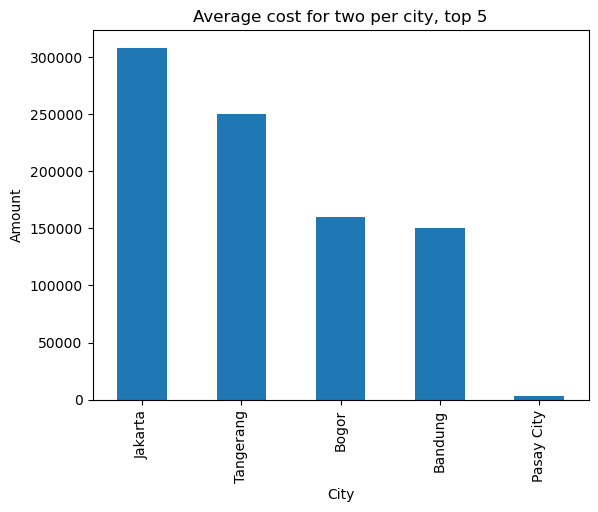

In [7]:
#Group by city and calculate average cost 
df.groupby("City")["Average Cost for two"].mean().sort_values(ascending=False).head().plot(kind="bar")
plt.title("Average cost for two per city, top 5")
plt.xlabel('City')
plt.ylabel('Amount')
plt.show()


In [8]:
#Cuisines total number of votes
data=df.groupby("Cuisines")["Votes"].sum().reset_index()

In [9]:
data[data["Votes"]!=0]

,Cuisines,Votes
0,Afghani,39
1,"Afghani, Mughlai, Chinese",2
3,"Afghani, North Indian, Pakistani, Arabian",3
4,African,373
5,"African, Portuguese",265
...,...,...
1820,"Western, Asian, Cafe",259
1821,"Western, Fusion, Fast Food",32
1822,World Cuisine,95
1823,"World Cuisine, Mexican, Italian",115


In [10]:
df.columns

Index(['Restaurant ID', 'Restaurant Name', 'Country Code', 'City', 'Address',
       'Locality', 'Locality Verbose', 'Longitude', 'Latitude', 'Cuisines',
       'Average Cost for two', 'Currency', 'Has Table booking',
       'Has Online delivery', 'Is delivering now', 'Switch to order menu',
       'Price range', 'Aggregate rating', 'Rating color', 'Rating text',
       'Votes'],
      dtype='object')

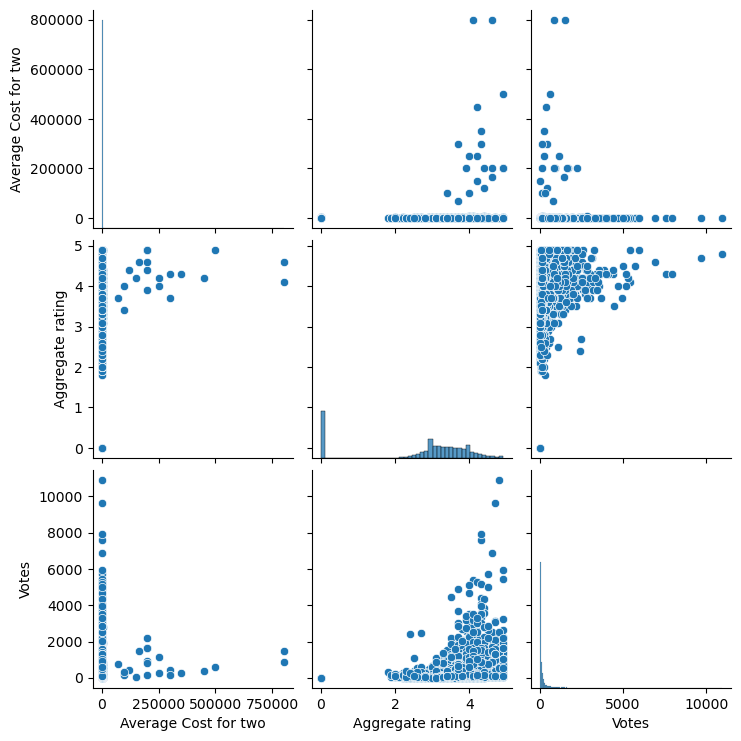

In [11]:
sns.pairplot(df[["Average Cost for two","Aggregate rating","Votes"]])

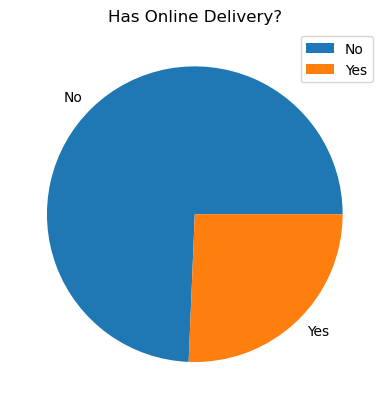

In [12]:
df["Has Online delivery"].value_counts().plot(kind="pie")
plt.title("Has Online Delivery?")
plt.ylabel("")
plt.legend()
plt.show()

In [13]:
df[["Aggregate rating","Rating text"]].sort_values(by="Aggregate rating",ascending=True).head(2300)

,Aggregate rating,Rating text
6615,0.0,Not rated
1994,0.0,Not rated
1995,0.0,Not rated
1996,0.0,Not rated
1997,0.0,Not rated
...,...,...
8716,2.4,Poor
4953,2.4,Poor
1771,2.4,Poor
8467,2.4,Poor


In [14]:
df=df[df["Rating text"]!="Not rated"]

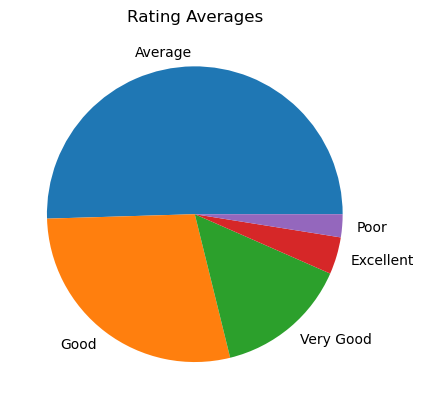

In [15]:
df['Rating text'].value_counts().plot(kind="pie")
plt.title("Rating Averages")
plt.ylabel("")
plt.show()

## Feature Engineering

In [16]:
X=df[['Average Cost for two', 'Has Table booking', 'Has Online delivery','Price range']]

In [17]:
#Above 2 below 2.5 ->poor
#Above 2.5 below 3.5 -> Average
#Above 3.5 below 4.0 -> Good
#Above 4 below 4.5 -> Very good
#Above 4.5 -> Excellent

In [18]:
y=df[["Aggregate rating"]]

In [19]:
X


,Average Cost for two,Has Table booking,Has Online delivery,Price range
0,1100,Yes,No,3
1,1200,Yes,No,3
2,4000,Yes,No,4
3,1500,No,No,4
4,1500,Yes,No,4
...,...,...,...,...
9546,80,No,No,3
9547,105,No,No,3
9548,170,No,No,4
9549,120,No,No,4


In [20]:
from sklearn import preprocessing
labelencoder = preprocessing.LabelEncoder()

In [21]:
X["Has Table booking"] = labelencoder.fit_transform(X["Has Table booking"]) # type: ignore # pyright: ignore[reportCallIssue] # pyright: ignore[reportArgumentType] # pyright: ignore[reportArgumentType] # pyright: ignore[reportArgumentType] # pyright: ignore[reportCallIssue] # pyright: ignore[reportCallIssue]

C:\Users\SU DE EP\AppData\Local\Temp\ipykernel_17888\3967662654.py:1: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  X["Has Table booking"] = labelencoder.fit_transform(X["Has Table booking"]) # type: ignore # pyright: ignore[reportCallIssue] # pyright: ignore[reportArgumentType] # pyright: ignore[reportArgumentType] # pyright: ignore[reportArgumentType] # pyright: ignore[reportCallIssue] # pyright: ignore[reportCallIssue]


In [22]:
X

,Average Cost for two,Has Table booking,Has Online delivery,Price range
0,1100,1,No,3
1,1200,1,No,3
2,4000,1,No,4
3,1500,0,No,4
4,1500,1,No,4
...,...,...,...,...
9546,80,0,No,3
9547,105,0,No,3
9548,170,0,No,4
9549,120,0,No,4


In [23]:
X["Has Online delivery"]=labelencoder.fit_transform(X["Has Online delivery"]) # type: ignore

C:\Users\SU DE EP\AppData\Local\Temp\ipykernel_17888\781100390.py:1: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  X["Has Online delivery"]=labelencoder.fit_transform(X["Has Online delivery"]) # type: ignore


In [24]:
X

,Average Cost for two,Has Table booking,Has Online delivery,Price range
0,1100,1,0,3
1,1200,1,0,3
2,4000,1,0,4
3,1500,0,0,4
4,1500,1,0,4
...,...,...,...,...
9546,80,0,0,3
9547,105,0,0,3
9548,170,0,0,4
9549,120,0,0,4


In [25]:
labelencoder.classes_

array(['No', 'Yes'], dtype=object)

In [26]:
#Has table booking 0 is no 1 is yes
#Has online delivery 0 is no 1 is yes

In [27]:
from sklearn.preprocessing import StandardScaler
scaler = StandardScaler()

In [28]:
X=scaler.fit_transform(X)

In [29]:
X

array([[-0.0190367 ,  2.37978283, -0.68302371,  1.10671644],
       [-0.0135729 ,  2.37978283, -0.68302371,  1.10671644],
       [ 0.13941344,  2.37978283, -0.68302371,  2.18135204],
       ...,
       [-0.06985002, -0.42020641, -0.68302371,  2.18135204],
       [-0.07258191, -0.42020641, -0.68302371,  2.18135204],
       [-0.07613338, -0.42020641, -0.68302371,  0.03208084]],
      shape=(7403, 4))

## Machine learning

In [30]:
from sklearn.model_selection import train_test_split

In [31]:
X_train, X_test, y_test, y_train =train_test_split(X,y, test_size=0.2, random_state=42)

In [32]:
from sklearn.metrics import mean_absolute_error, mean_squared_error
import numpy as np

In [33]:
def modelresults(prediction):
    print("Mean absolute error on model is{}".format(mean_absolute_error(y_test,prediction)))
    print("Root mean squared error on model is {}".format(np.sqrt(mean_squared_error(y_test,prediction))))

In [34]:
from sklearn.linear_model import LinearRegression
lr = LinearRegression()

In [35]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

lr.fit(X_train, y_train)

,fit_intercept,True
,copy_X,True
,tol,1e-06
,n_jobs,None
,positive,False


In [36]:
predictionsfromlr =lr.predict(X_test)

In [37]:
modelresults(predictionsfromlr)

Mean absolute error on model is0.4012400680712769
Root mean squared error on model is 0.5056738815663484


In [38]:
from sklearn.svm import SVR
from sklearn.model_selection import GridSearchCV

In [39]:
svrmodel=SVR()

In [40]:
param_gridsvr = {"C": [0.1,0.5], "kernel": ["linear",  "poly"], "degree":[2]}

In [41]:
gridsvr=GridSearchCV(svrmodel,param_gridsvr)
gridsvr.fit(X_train,y_train)

c:\ProgramData\anaconda3\Lib\site-packages\sklearn\utils\validation.py:1406: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples, ), for example using ravel().
  y = column_or_1d(y, warn=True)
c:\ProgramData\anaconda3\Lib\site-packages\sklearn\utils\validation.py:1406: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples, ), for example using ravel().
  y = column_or_1d(y, warn=True)
c:\ProgramData\anaconda3\Lib\site-packages\sklearn\utils\validation.py:1406: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples, ), for example using ravel().
  y = column_or_1d(y, warn=True)
c:\ProgramData\anaconda3\Lib\site-packages\sklearn\utils\validation.py:1406: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples,

,estimator,SVR()
,param_grid,"{'C': [0.1, 0.5], 'degree': [2], 'kernel': ['linear', 'poly']}"
,scoring,None
,n_jobs,None
,refit,True
,cv,None
,verbose,0
,pre_dispatch,'2*n_jobs'
,error_score,nan
,return_train_score,False
,kernel,'linear'


In [42]:
predsgridsvr = gridsvr.predict(X_test)

In [43]:
modelresults(predsgridsvr)

Mean absolute error on model is0.398659090620775
Root mean squared error on model is 0.5080167129195692


In [44]:
from sklearn.tree import DecisionTreeRegressor

In [45]:
param_grid = {
    "max_depth" : [10,30],
    "min_samples_leaf" : [1,2],
    "min_samples_split" : [2,5]
}

In [46]:
treemodel = DecisionTreeRegressor()

In [47]:
grid_tree=GridSearchCV(estimator=treemodel, param_grid=param_grid)

In [48]:
grid_tree.fit(X_train,y_train)

,estimator,DecisionTreeRegressor()
,param_grid,"{'max_depth': [10, 30], 'min_samples_leaf': [1, 2], 'min_samples_split': [2, 5]}"
,scoring,None
,n_jobs,None
,refit,True
,cv,None
,verbose,0
,pre_dispatch,'2*n_jobs'
,error_score,nan
,return_train_score,False
,criterion,'squared_error'


In [49]:
treepredictions=grid_tree.predict(X_test)

In [50]:
modelresults(treepredictions)

Mean absolute error on model is0.3555485256737986
Root mean squared error on model is 0.448932682691313


In [51]:
from sklearn.ensemble import RandomForestRegressor

In [52]:
rfrmodel = RandomForestRegressor()

In [53]:
param_gridsrfr={"max_depth":[5,15], "n_estimators":[2,5,10]}

In [54]:
gridrfr=GridSearchCV(rfrmodel,param_gridsrfr)

In [55]:
gridrfr.fit(X_train,y_train)

c:\ProgramData\anaconda3\Lib\site-packages\sklearn\base.py:1365: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples,), for example using ravel().
  return fit_method(estimator, *args, **kwargs)
c:\ProgramData\anaconda3\Lib\site-packages\sklearn\base.py:1365: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples,), for example using ravel().
  return fit_method(estimator, *args, **kwargs)
c:\ProgramData\anaconda3\Lib\site-packages\sklearn\base.py:1365: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples,), for example using ravel().
  return fit_method(estimator, *args, **kwargs)
c:\ProgramData\anaconda3\Lib\site-packages\sklearn\base.py:1365: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples,), for

,estimator,RandomForestRegressor()
,param_grid,"{'max_depth': [5, 15], 'n_estimators': [2, 5, ...]}"
,scoring,None
,n_jobs,None
,refit,True
,cv,None
,verbose,0
,pre_dispatch,'2*n_jobs'
,error_score,nan
,return_train_score,False
,n_estimators,10


In [56]:
RandomForestpredictions=gridrfr.predict(X_test)


In [57]:
modelresults(RandomForestpredictions)

Mean absolute error on model is0.3529432266233975
Root mean squared error on model is 0.44756724416723526


In [58]:
gridrfr.best_params_

{'max_depth': 5, 'n_estimators': 10}

In [59]:
grid_tree.best_params_

{'max_depth': 10, 'min_samples_leaf': 2, 'min_samples_split': 5}

In [60]:
from sklearn.neighbors import KNeighborsRegressor
from sklearn.model_selection import GridSearchCV

knn = KNeighborsRegressor()
knn_param_grid = {"n_neighbors": [9,10,12,14,15]}
knn_grid_search = GridSearchCV(knn, knn_param_grid, cv=5)

knn_grid_search.fit(X_train, y_train)

,estimator,KNeighborsRegressor()
,param_grid,"{'n_neighbors': [9, 10, ...]}"
,scoring,None
,n_jobs,None
,refit,True
,cv,5
,verbose,0
,pre_dispatch,'2*n_jobs'
,error_score,nan
,return_train_score,False
,n_neighbors,15


In [61]:
knnpreds=knn_grid_search.predict(X_test)

In [62]:
modelresults(knnpreds)

Mean absolute error on model is0.36435291469727665
Root mean squared error on model is 0.4594729616700143


In [63]:
knn_grid_search.best_params_

{'n_neighbors': 15}

In [64]:
from sklearn.ensemble import AdaBoostRegressor
ada=AdaBoostRegressor()
ada_param_grid = {"n_estimators": [50,100,200],
                  "learning_rate": [0.1,0.5,1] }

ada_grid_search=GridSearchCV(ada,ada_param_grid)

            
                  

In [65]:
ada_grid_search.fit(X_train,y_train)

c:\ProgramData\anaconda3\Lib\site-packages\sklearn\utils\validation.py:1406: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples, ), for example using ravel().
  y = column_or_1d(y, warn=True)
c:\ProgramData\anaconda3\Lib\site-packages\sklearn\utils\validation.py:1406: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples, ), for example using ravel().
  y = column_or_1d(y, warn=True)
c:\ProgramData\anaconda3\Lib\site-packages\sklearn\utils\validation.py:1406: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples, ), for example using ravel().
  y = column_or_1d(y, warn=True)
c:\ProgramData\anaconda3\Lib\site-packages\sklearn\utils\validation.py:1406: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples,

,estimator,AdaBoostRegressor()
,param_grid,"{'learning_rate': [0.1, 0.5, ...], 'n_estimators': [50, 100, ...]}"
,scoring,None
,n_jobs,None
,refit,True
,cv,None
,verbose,0
,pre_dispatch,'2*n_jobs'
,error_score,nan
,return_train_score,False
,estimator,None


In [66]:
ada_preds=ada_grid_search.predict(X_test)

In [67]:
modelresults(ada_preds)

Mean absolute error on model is0.3673765277346693
Root mean squared error on model is 0.4606990189420648


In [68]:
gridrfr

,estimator,RandomForestRegressor()
,param_grid,"{'max_depth': [5, 15], 'n_estimators': [2, 5, ...]}"
,scoring,None
,n_jobs,None
,refit,True
,cv,None
,verbose,0
,pre_dispatch,'2*n_jobs'
,error_score,nan
,return_train_score,False
,n_estimators,10


In [69]:
import joblib
joblib.dump(gridrfr,"mlmodel.pkl")

['mlmodel.pkl']

In [70]:
scaler

,copy,True
,with_mean,True
,with_std,True


In [71]:
joblib.dump(scaler,"Scaler.pkl")

['Scaler.pkl']